# 01. Pre-processing and Exploratory Data Analysis

Goal: load the three raw files, clean them into two analysis tables, and get a descriptive picture of Messi's goals.
This notebook **describes** the data. Hypothesis tests come in `02_hypothesis_testing` and the prediction model in `03_ml_model`.

**Data**
- `messi_all_goals.csv` (Kaggle): one row per club goal. Only matches where Messi scored appear.
- `statsbomb/matches.csv` and `statsbomb/appearances.csv` (StatsBomb open data, downloaded by `src/fetch_statsbomb.py`): one row per La Liga or Ligue 1 match Messi played, including matches without a goal, with minutes played.

**Before running:** `python src/fetch_statsbomb.py` once (needs internet). The cleaning logic lives in `src/clean.py` and `src/clean_statsbomb.py`; this notebook calls those functions and saves the clean tables to `data/clean/`.

**Table of contents**
1. Importing libraries
2. Loading the datasets
3. Pre-processing
    - 3.1 Issues found in the raw data
    - 3.2 Cleaning the goals data
    - 3.3 Building the league match table
    - 3.4 Key checks
4. Exploratory Data Analysis
    - 4.1 Overview
    - 4.2 Goals over time
    - 4.3 What the goals look like
    - 4.4 Match context
    - 4.5 Assists
    - 4.6 Goals per 90 minutes (StatsBomb)
5. Observations and hypotheses

## 1. Importing libraries

In [6]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook lives in notebooks/, so the repository root is one level up.
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "src"))

import clean            # src/clean.py: cleaning for the Kaggle goals file
import clean_sb  # src/clean_statsbomb.py: builds the league match table

RAW_GOALS_PATH = REPO_ROOT / "data" / "raw" / "messi_all_goals.csv"
STATSBOMB_DIR = REPO_ROOT / "data" / "raw"
CLEAN_GOALS_PATH = REPO_ROOT / "data" / "clean" / "messi_goals_clean.csv"
LEAGUE_MATCHES_PATH = REPO_ROOT / "data" / "clean" / "messi_league_matches.csv"
FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Minute buckets in time order, so charts do not sort them alphabetically.
MINUTE_BUCKET_ORDER = ["0-15", "16-30", "31-45", "46-60", "61-75", "76-90", "91+"]

## 2. Loading the datasets

The goals file is read with every column as text, so pandas does not guess any types before cleaning.

In [7]:
raw_goals = clean.load_raw_data(RAW_GOALS_PATH)
raw_sb_matches = pd.read_csv(STATSBOMB_DIR / "matches.csv")
raw_sb_appearances = pd.read_csv(STATSBOMB_DIR / "appearances.csv")

raw_datasets = {
    "Kaggle goals": raw_goals,
    "StatsBomb matches": raw_sb_matches,
    "StatsBomb appearances": raw_sb_appearances,
}

dataset_overview = pd.DataFrame(
    {
        "rows": [len(frame) for frame in raw_datasets.values()],
        "columns": [frame.shape[1] for frame in raw_datasets.values()],
        "missing cells": [int(frame.isna().sum().sum()) for frame in raw_datasets.values()],
        "duplicate rows": [int(frame.duplicated().sum()) for frame in raw_datasets.values()],
    },
    index=raw_datasets.keys(),
)
dataset_overview

,rows,columns,missing cells,duplicate rows
Kaggle goals,790,16,0,0
StatsBomb matches,578,13,0,0
StatsBomb appearances,578,5,0,0


In [3]:
raw_goals.head(3)

,competition,match_stage,date,venue,club,opponent,match_score,player_position,goal_minute,score_at_goal,goal_type,assist_player,season,goal_decade,is_home_goal,goal_minute_bucket
0,2ª B - Grupo III,2,9/5/2004,Home,FC Barcelona B,Girona FC,1:02,LW,65,1:02,Left-footed shot,Dani Fernández,2004-05,2000s,TRUE,61-75
1,2ª B - Grupo III,4,9/18/2004,Home,FC Barcelona B,RCD Espanyol B,2:00,LW,88,2:00,Left-footed shot,Dani Fernández,2004-05,2000s,TRUE,76-90
2,2ª B - Grupo III,10,10/31/2004,Away,FC Barcelona B,Villajoyosa CF,2:01,AM,2,0:01,Not reported,Not Applicable,2004-05,2000s,FALSE,0-15


In [4]:
raw_sb_matches.merge(raw_sb_appearances, on="match_id").head(3)

,match_id,date,season,age,competition,match_week,club,opponent,venue,home_score,away_score,goals_for,goals_against,started,minutes_played,starting_position,end_reason
0,68353,2004-10-16,2004/2005,17,La Liga,7,Barcelona,Espanyol,away,0,1,1,0,0,9,Right Center Midfield,Final Whistle
1,68313,2004-10-24,2004/2005,17,La Liga,8,Barcelona,Osasuna,home,3,0,3,0,0,18,Left Wing,Final Whistle
2,68314,2004-12-04,2004/2005,17,La Liga,14,Barcelona,Málaga,home,4,0,4,0,0,9,Right Center Back,Final Whistle


## 3. Pre-processing

### 3.1 Issues found in the raw data

None of the files has missing cells or duplicate rows. The problems are in how values are written and in what each file leaves out. The cell after the table recomputes every count from the raw files.

| # | File | Issue | Rows affected | How it is handled | Function |
|---|---|---|---|---|---|
| 1 | Goals | Goals for the reserve team `FC Barcelona B` (2004-05, third tier) are not comparable to first-team goals | 6 | Removed | `clean.remove_excluded_clubs` |
| 2 | Goals | `date` is text in month/day/year form | all | Parsed as a date; `year` and `month` added | `clean.clean_dates` |
| 3 | Goals | `match_stage` mixes round names and league matchday numbers | 235 names | Split into `stage_name` and `matchday` | `clean.clean_stage` |
| 4 | Goals | Scores look like clock times (`1:02` means 1-2, home:away) | all | Parsed and turned to Messi's team point of view using `venue`; score before the goal and game state added | `clean.clean_scores` |
| 5 | Goals | `Not Applicable` in `assist_player` means no assist | 240 | `has_assist` flag; `assist_player` left blank | `clean.clean_assists` |
| 6 | Goals | 13 goal types, some with a handful of rows; `Not reported` is missing | 13 types, 5 missing | Grouped into 7 (`Unknown` for missing); raw value kept | `clean.clean_goal_types` |
| 7 | Goals | No match identifier | all | `match_id` from date, club and opponent | `clean.add_match_id` |
| 8 | StatsBomb | Two files, names and formats differ from Kaggle (`La Liga`, `Barcelona`, `2004/2005`, `home`) | all | Joined on `match_id`; names mapped to the Kaggle form | `clean_statsbomb.standardize_names` |
| 9 | StatsBomb | No Messi goals per match | all | Counted from the clean goals file per (date, competition); 0 when he did not score | `clean_statsbomb.add_messi_goals` |
| 10 | StatsBomb | As a substitute, the position is that of the player he replaced (for example Right Back) | 59 | `position_reliable` is True only for starts | `clean_statsbomb.add_position_columns` |
| 11 | StatsBomb | A substitute recorded with 90 minutes | 1 | Kept and flagged | `clean_statsbomb.add_quality_flags` |
| 12 | StatsBomb | Minutes are capped at 90 (no stoppage time) | all | Kept; goals per 90 is slightly overstated | none |

In [8]:
issue_counts = pd.Series(
    {
        "1. FC Barcelona B goals": int(raw_goals["club"].isin(clean.EXCLUDED_CLUBS).sum()),
        "3. match_stage values that are names": int((~raw_goals["match_stage"].str.isdigit()).sum()),
        "5. Not Applicable assists": int((raw_goals["assist_player"] == "Not Applicable").sum()),
        "6. Distinct goal types": raw_goals["goal_type"].nunique(),
        "6. Not reported goal types": int((raw_goals["goal_type"] == "Not reported").sum()),
        "10. Substitute appearances": int((raw_sb_appearances["started"] == 0).sum()),
        "11. Substitute with 90 minutes": int(
            ((raw_sb_appearances["started"] == 0) & (raw_sb_appearances["minutes_played"] >= 90)).sum()
        ),
        "12. Maximum minutes in one match": int(raw_sb_appearances["minutes_played"].max()),
    },
    name="count",
)
issue_counts.to_frame()

,count
1. FC Barcelona B goals,6
3. match_stage values that are names,235
5. Not Applicable assists,240
6. Distinct goal types,13
6. Not reported goal types,5
10. Substitute appearances,59
11. Substitute with 90 minutes,1
12. Maximum minutes in one match,90


In [9]:
# Issue 4: raw scores are home:away, written like clock times (zero-padded after the colon).
raw_goals[["date", "venue", "opponent", "match_score", "score_at_goal"]].sample(5, random_state=1)

,date,venue,opponent,match_score,score_at_goal
579,1/6/2019,Away,Getafe CF,1:02,0:01
148,11/7/2010,Away,Getafe CF,1:03,0:01
247,4/14/2012,Away,Levante UD,1:02,1:01
435,1/9/2016,Home,Granada CF,4:00,3:00
60,11/26/2008,Away,Sporting CP,2:05,0:03


### 3.2 Cleaning the goals data

`clean.clean_messi_goals` runs issues 1 to 7 in order, prints its own sanity checks and saves the result to `data/clean/messi_goals_clean.csv`.

In [10]:
clean_goals = clean.clean_messi_goals(RAW_GOALS_PATH, CLEAN_GOALS_PATH)
print(f"Rows: {len(raw_goals)} raw -> {len(clean_goals)} clean, columns: {clean_goals.shape[1]}")

Removed 6 goals from excluded clubs: ['FC Barcelona B']
Rows: 784
Rows where team goals after > final team goals: 0
Rows where opponent goals after > final opponent goals: 0
Rows with negative 'team_goals_before': 0
Rows where is_home_goal disagrees with venue: 0
Matches where Messi goals > team final goals: 0
League rows without matchday: 0
Saved clean data to c:\PTIT\Python\Project\messi-goals-analytics\data\clean\messi_goals_clean.csv
Rows: 790 raw -> 784 clean, columns: 30


In [11]:
# The score columns after cleaning, for away games (the raw score had to be swapped).
clean_goals.loc[
    clean_goals["venue"] == "Away",
    ["date", "opponent", "team_goals_final", "opponent_goals_final", "match_result", "game_state_before"],
].head(5)

,date,opponent,team_goals_final,opponent_goals_final,match_result,game_state_before
5,2006-01-29,RCD Mallorca,3,0,W,Winning
6,2006-01-29,RCD Mallorca,3,0,W,Winning
9,2006-08-28,Celta de Vigo,3,2,W,Drawing
11,2006-09-27,SV Werder Bremen,1,1,D,Losing
16,2007-03-17,Recreativo Huelva,4,0,W,Winning


In [12]:
# How the 13 raw goal types were grouped.
pd.crosstab(clean_goals["goal_type_raw"], clean_goals["goal_type"])

goal_type,Free kick,Header,Left foot,Other,Penalty,Right foot,Unknown
goal_type_raw,,,,,,,
Chest,0,0,0,2,0,0,0
Counter attack goal,0,0,0,1,0,0,0
Deflected shot on goal,0,0,0,2,0,0,0
Direct free kick,59,0,0,0,0,0,0
Header,0,28,0,0,0,0,0
Left-footed shot,0,0,490,0,0,0,0
Long distance kick,0,0,0,1,0,0,0
Not reported,0,0,0,0,0,0,3
Penalty,0,0,0,0,88,0,0


### 3.3 Building the league match table

`clean_statsbomb.build_league_matches` handles issues 8 to 11 and adds Messi's goals per match from the clean goals file saved above.
Opponent names are spelled differently in the two sources (`Sevilla` vs `Sevilla FC`), so the join key is date plus competition.

In [14]:
league_matches = clean_sb.build_league_matches(
    STATSBOMB_DIR / "appearances.csv",
    STATSBOMB_DIR / "matches.csv",
    CLEAN_GOALS_PATH,
)
league_matches.to_csv(LEAGUE_MATCHES_PATH, index=False)
print(f"Saved {len(league_matches)} matches to {LEAGUE_MATCHES_PATH.relative_to(REPO_ROOT)}")
league_matches.head(3)

Matches: 578, appearances: 578, joined: 578 (lost 0)
League goals in the Kaggle file: 496, matched to a StatsBomb match: 496
Saved 578 matches to data\clean\messi_league_matches.csv


,match_id,date,season,age,club,competition,matchday,opponent,venue,started,starting_position,position_group,minutes_played,end_reason,team_goals,opponent_goals,match_result,team_goals_without_messi,messi_goals,scored,position_reliable,flag_sub_with_90_minutes
0,68353,2004-10-16,2004-05,17,FC Barcelona,LaLiga,7,Espanyol,Away,False,Right Center Midfield,Other,9,Final Whistle,1,0,W,1,0,False,False,False
1,68313,2004-10-24,2004-05,17,FC Barcelona,LaLiga,8,Osasuna,Home,False,Left Wing,Wing,18,Final Whistle,3,0,W,3,0,False,False,False
2,68314,2004-12-04,2004-05,17,FC Barcelona,LaLiga,14,Málaga,Home,False,Right Center Back,Other,9,Final Whistle,4,0,W,4,0,False,False,False


### 3.4 Key checks

If any check fails, fix the function in `src/`, then rerun this notebook from the top.

In [17]:
kaggle_league_goals = int(clean_goals["competition"].isin(["LaLiga", "Ligue 1"]).sum())
goals_per_match = clean_goals.groupby("match_id").size()
team_goals_per_match = clean_goals.groupby("match_id")["team_goals_final"].first()

key_checks = {
    "Goals: raw rows minus FC Barcelona B": (
        len(clean_goals) == len(raw_goals) - int(raw_goals["club"].isin(clean.EXCLUDED_CLUBS).sum())
    ),
    "Goals: score after the goal never above the final score": (
        (clean_goals["team_goals_after"] <= clean_goals["team_goals_final"]).all()
        and (clean_goals["opponent_goals_after"] <= clean_goals["opponent_goals_final"]).all()
    ),
    "Goals: Messi goals in a match never above team goals": (goals_per_match <= team_goals_per_match).all(),
    "Goals: matchday only for league rows": (
        clean_goals.loc[clean_goals["stage_name"] == "League", "matchday"].notna().all()
        and clean_goals.loc[clean_goals["stage_name"] != "League", "matchday"].isna().all()
    ),
    "Matches: one row per match, every name mapped": (
        league_matches["match_id"].is_unique
        and league_matches[["competition", "club"]].notna().all().all()
    ),
    "Matches: 494 of 496 league goals matched": (
    int(league_matches["messi_goals"].sum()) == kaggle_league_goals
    ),
    "Matches: Messi goals never above team goals": (
        league_matches["messi_goals"] <= league_matches["team_goals"]
    ).all(),
    "Matches: minutes between 1 and 90": league_matches["minutes_played"].between(1, 90).all(),
}

key_check_results = pd.Series(key_checks, name="passed")
print(key_check_results.to_string())
assert key_check_results.all(), "At least one check failed. See the table above."

Goals: raw rows minus FC Barcelona B                       True
Goals: score after the goal never above the final score    True
Goals: Messi goals in a match never above team goals       True
Goals: matchday only for league rows                       True
Matches: one row per match, every name mapped              True
Matches: 494 of 496 league goals matched                   True
Matches: Messi goals never above team goals                True
Matches: minutes between 1 and 90                          True


**Manual check of the score format.** The matches with the most Messi goals are easy to look up. If one of these final scores is wrong, the home:away assumption in `clean.parse_score_text` is wrong.

In [18]:
top_matches = (
    clean_goals.groupby("match_id")
    .agg(
        date=("date", "first"),
        competition=("competition", "first"),
        opponent=("opponent", "first"),
        venue=("venue", "first"),
        messi_goals=("goal_number_in_match", "max"),
        team_goals=("team_goals_final", "first"),
        opponent_goals=("opponent_goals_final", "first"),
    )
    .sort_values(["messi_goals", "date"], ascending=[False, True])
    .head(5)
)
top_matches

,date,competition,opponent,venue,messi_goals,team_goals,opponent_goals
match_id,,,,,,,
146,2012-03-07,UEFA Champions League,Bayer 04 Leverkusen,Home,5,7,1
84,2010-04-06,UEFA Champions League,Arsenal FC,Home,4,4,1
144,2012-02-19,LaLiga,Valencia CF,Home,4,5,1
158,2012-05-05,LaLiga,RCD Espanyol Barcelona,Home,4,4,0
184,2013-01-27,LaLiga,CA Osasuna,Home,4,5,1


**Column roles for the ML part.** Only `pre_match` columns may be used as features. `post_match` columns are known only after the match (for example `team_goals` already contains Messi's goals) and would leak the answer.

In [19]:
pd.Series(clean_sb.COLUMN_ROLES, name="role").rename_axis("column").to_frame().sort_values("role")

,role
column,
match_id,id_or_quality
position_reliable,id_or_quality
flag_sub_with_90_minutes,id_or_quality
date,id_or_quality
minutes_played,post_match
team_goals_without_messi,post_match
match_result,post_match
opponent_goals,post_match
team_goals,post_match


## 4. Exploratory Data Analysis

The EDA reads the two clean files back from disk, so it uses exactly what the later notebooks will use.
- In the goals table every row is one goal, so only matches where Messi scored appear and per-game rates cannot be computed from it. Section 4.6 uses the league match table for that.
- The data covers club goals only (FC Barcelona, PSG, Inter Miami). There are no national team goals.
- The last season (2025-26) is partial; the data ends on 2026-03-07.

In [20]:
goals = pd.read_csv(CLEAN_GOALS_PATH, parse_dates=["date"])
goals["goal_minute_bucket"] = pd.Categorical(
    goals["goal_minute_bucket"], categories=MINUTE_BUCKET_ORDER, ordered=True
)
league_matches = pd.read_csv(LEAGUE_MATCHES_PATH, parse_dates=["date"])

print(f"Goals: {len(goals)} rows, league matches: {len(league_matches)} rows")

Goals: 784 rows, league matches: 578 rows


### 4.1 Overview

In [21]:
matches = goals["match_id"].nunique()
summary = pd.Series(
    {
        "Goals (rows)": len(goals),
        "Matches with at least one goal": matches,
        "Goals per scoring match": round(len(goals) / matches, 2),
        "Seasons": goals["season"].nunique(),
        "First goal": goals["date"].min().date(),
        "Last goal": goals["date"].max().date(),
        "Competitions": goals["competition"].nunique(),
        "Opponents": goals["opponent"].nunique(),
        "Assisting players": goals["assist_player"].nunique(),
    },
    name="value",
)
summary.to_frame()

,value
Goals (rows),784
Matches with at least one goal,512
Goals per scoring match,1.53
Seasons,22
First goal,2005-05-01
Last goal,2026-03-07
Competitions,12
Opponents,121
Assisting players,84


In [22]:
goals_by_club = goals["club"].value_counts().rename("goals").to_frame()
goals_by_club["share"] = (goals_by_club["goals"] / len(goals)).round(3)
goals_by_club

,goals,share
club,,
FC Barcelona,672,0.857
Inter Miami CF,80,0.102
Paris Saint-Germain,32,0.041


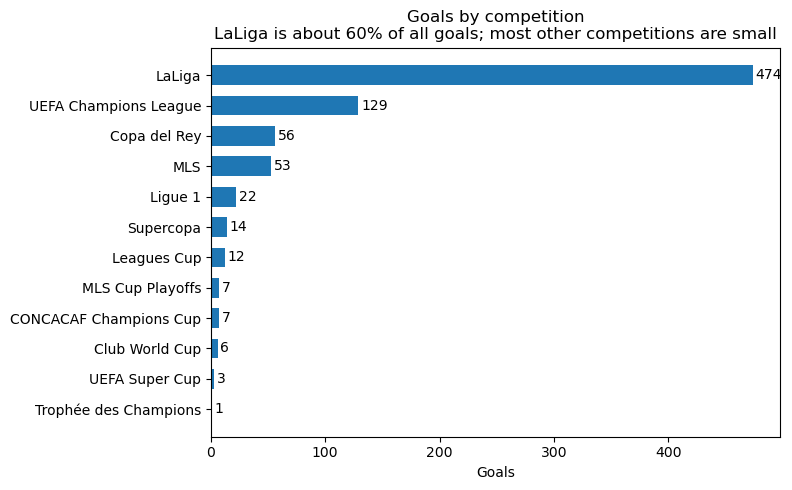

In [24]:
goals_by_competition = goals["competition"].value_counts().sort_values()

figure, axes = plt.subplots(figsize=(8, 5))
bars = axes.barh(goals_by_competition.index, goals_by_competition.values, height=0.65)
axes.bar_label(bars, padding=2)
axes.set_xlabel("Goals")
axes.set_title("Goals by competition\nLaLiga is about 60% of all goals; most other competitions are small")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_goals_by_competition.png", dpi=150)

### 4.2 Goals over time

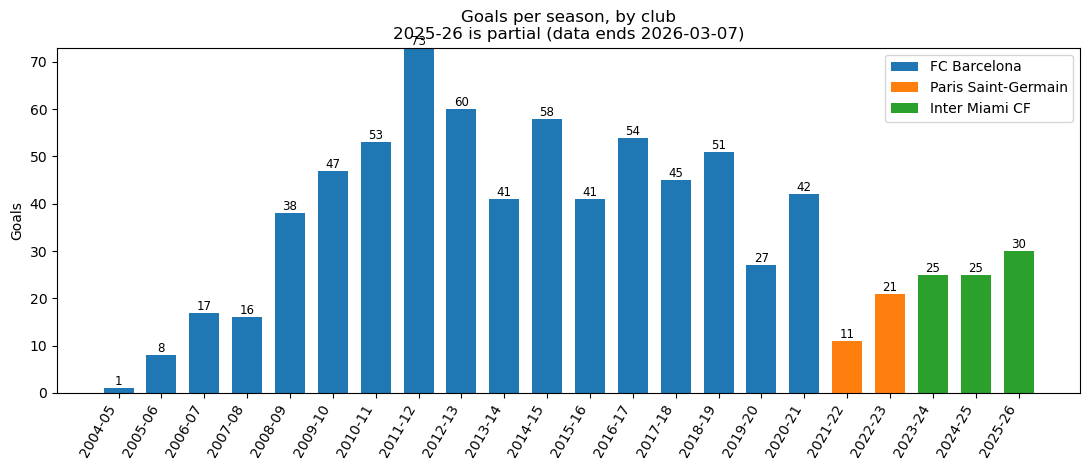

In [26]:
goals_by_season_club = (
    goals.groupby(["season", "club"]).size().unstack(fill_value=0)
)
club_order = ["FC Barcelona", "Paris Saint-Germain", "Inter Miami CF"]
goals_by_season_club = goals_by_season_club[club_order]

figure, axes = plt.subplots(figsize=(11, 4.8))
bottoms = np.zeros(len(goals_by_season_club))
x_positions = np.arange(len(goals_by_season_club))

for club in club_order:
    values = goals_by_season_club[club].values
    axes.bar(
        x_positions, values, bottom=bottoms, width=0.7, label=club,
    )
    bottoms += values

# Total above each bar.
for x_position, total in zip(x_positions, bottoms):
    axes.text(x_position, total, f"{int(total)}", ha="center", va="bottom", fontsize=8.5)

axes.set_xticks(x_positions)
axes.set_xticklabels(goals_by_season_club.index, rotation=60, ha="right")
axes.set_ylabel("Goals")
axes.legend()
axes.set_title("Goals per season, by club\n2025-26 is partial (data ends 2026-03-07)")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_goals_by_season.png", dpi=150)

In [27]:
# Table view of the same chart.
goals_by_season_club.assign(total=goals_by_season_club.sum(axis=1))

club,FC Barcelona,Paris Saint-Germain,Inter Miami CF,total
season,,,,
2004-05,1,0,0,1
2005-06,8,0,0,8
2006-07,17,0,0,17
2007-08,16,0,0,16
2008-09,38,0,0,38
2009-10,47,0,0,47
2010-11,53,0,0,53
2011-12,73,0,0,73
2012-13,60,0,0,60


### 4.3 What the goals look like

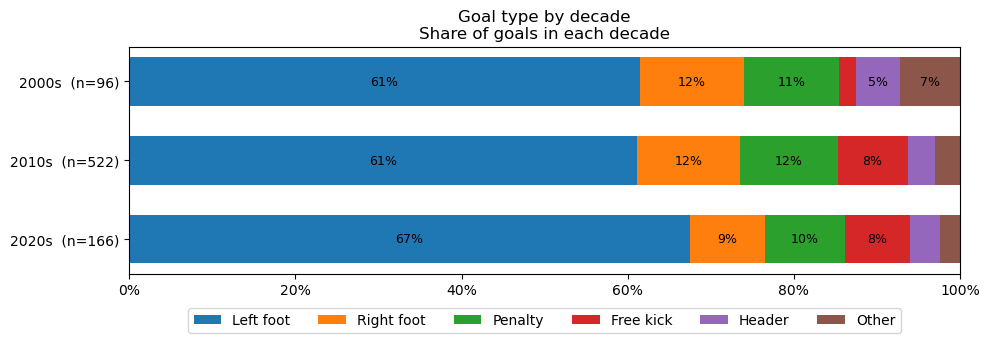

In [28]:
# Fold the 3 "Unknown" goal types into "Other" so the chart has six groups.
goals["goal_type_chart"] = goals["goal_type"].replace({"Unknown": "Other"})
goal_type_order = ["Left foot", "Right foot", "Penalty", "Free kick", "Header", "Other"]
decade_order = ["2000s", "2010s", "2020s"]

type_counts = (
    pd.crosstab(goals["goal_decade"], goals["goal_type_chart"])
    .reindex(index=decade_order, columns=goal_type_order, fill_value=0)
)
type_shares = type_counts.div(type_counts.sum(axis=1), axis=0)

figure, axes = plt.subplots(figsize=(10, 3.6))
left_edges = np.zeros(len(type_shares))
y_positions = np.arange(len(type_shares))

for goal_type in goal_type_order:
    shares = type_shares[goal_type].values
    axes.barh(
        y_positions, shares, left=left_edges, height=0.62, label=goal_type,
    )
    # Label segments wide enough to hold the text.
    for y_position, share, left_edge in zip(y_positions, shares, left_edges):
        if share >= 0.045:
            axes.text(
                left_edge + share / 2, y_position, f"{share:.0%}",
                ha="center", va="center", fontsize=9,
            )
    left_edges += shares

row_labels = [
    f"{decade}  (n={int(total)})" for decade, total in zip(type_counts.index, type_counts.sum(axis=1))
]
axes.set_yticks(y_positions)
axes.set_yticklabels(row_labels)
axes.invert_yaxis()
axes.set_xlim(0, 1)
axes.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axes.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.12))
axes.set_title("Goal type by decade\nShare of goals in each decade")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_goal_type_by_decade.png", dpi=150)

In [29]:
# Table view: counts behind the chart.
type_counts.assign(total=type_counts.sum(axis=1))

goal_type_chart,Left foot,Right foot,Penalty,Free kick,Header,Other,total
goal_decade,,,,,,,
2000s,59,12,11,2,5,7,96
2010s,319,65,61,44,17,16,522
2020s,112,15,16,13,6,4,166


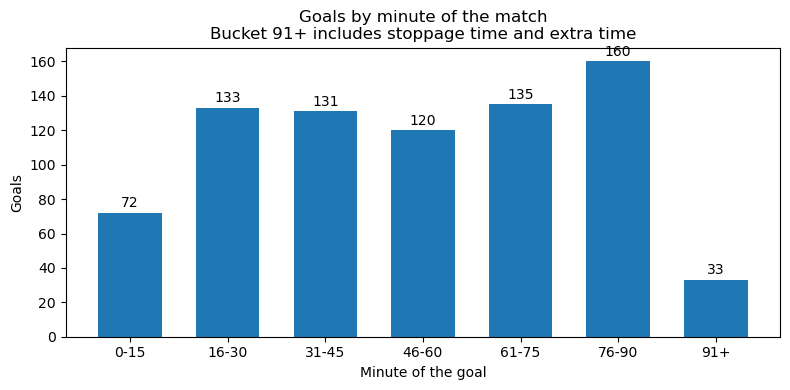

In [30]:
goals_by_bucket = goals["goal_minute_bucket"].value_counts().reindex(MINUTE_BUCKET_ORDER)

figure, axes = plt.subplots(figsize=(8, 4))
bars = axes.bar(goals_by_bucket.index.astype(str), goals_by_bucket.values, width=0.65)
axes.bar_label(bars, padding=2)
axes.set_xlabel("Minute of the goal")
axes.set_ylabel("Goals")
axes.set_title("Goals by minute of the match\nBucket 91+ includes stoppage time and extra time")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_goals_by_minute.png", dpi=150)

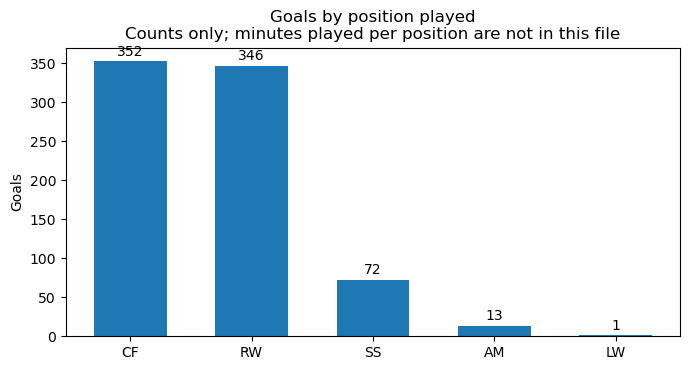

In [31]:
goals_by_position = goals["player_position"].value_counts()

figure, axes = plt.subplots(figsize=(7, 3.8))
bars = axes.bar(goals_by_position.index, goals_by_position.values, width=0.6)
axes.bar_label(bars, padding=2)
axes.set_ylabel("Goals")
axes.set_title("Goals by position played\nCounts only; minutes played per position are not in this file")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_goals_by_position.png", dpi=150)

### 4.4 Match context

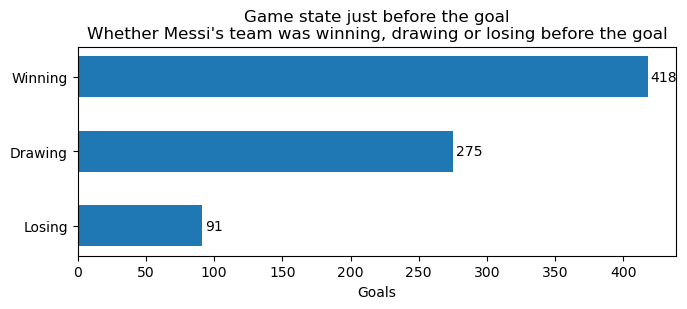

In [32]:
state_order = ["Winning", "Drawing", "Losing"]
goals_by_state = goals["game_state_before"].value_counts().reindex(state_order)

figure, axes = plt.subplots(figsize=(7, 3.2))
bars = axes.barh(goals_by_state.index, goals_by_state.values, height=0.55)
axes.bar_label(bars, padding=2)
axes.invert_yaxis()
axes.set_xlabel("Goals")
axes.set_title("Game state just before the goal\nWhether Messi's team was winning, drawing or losing before the goal")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_game_state.png", dpi=150)

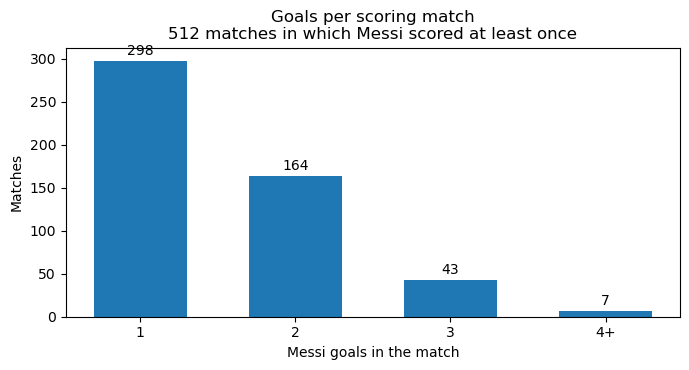

In [33]:
goals_in_match = goals.groupby("match_id").size()
capped = goals_in_match.clip(upper=4)
match_counts = capped.value_counts().sort_index()
match_labels = [str(value) if value < 4 else "4+" for value in match_counts.index]

figure, axes = plt.subplots(figsize=(7, 3.8))
bars = axes.bar(match_labels, match_counts.values, width=0.6)
axes.bar_label(bars, padding=2)
axes.set_xlabel("Messi goals in the match")
axes.set_ylabel("Matches")
axes.set_title(f"Goals per scoring match\n{matches} matches in which Messi scored at least once")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_goals_per_match.png", dpi=150)

In [34]:
home_away = pd.crosstab(goals["venue"], goals["match_result"]).reindex(columns=["W", "D", "L"], fill_value=0)
home_away["total"] = home_away.sum(axis=1)
print("Goals by venue and the final result of the match:")
home_away

Goals by venue and the final result of the match:


match_result,W,D,L,total
venue,,,,
Away,271,34,13,318
Home,424,29,13,466


### 4.5 Assists

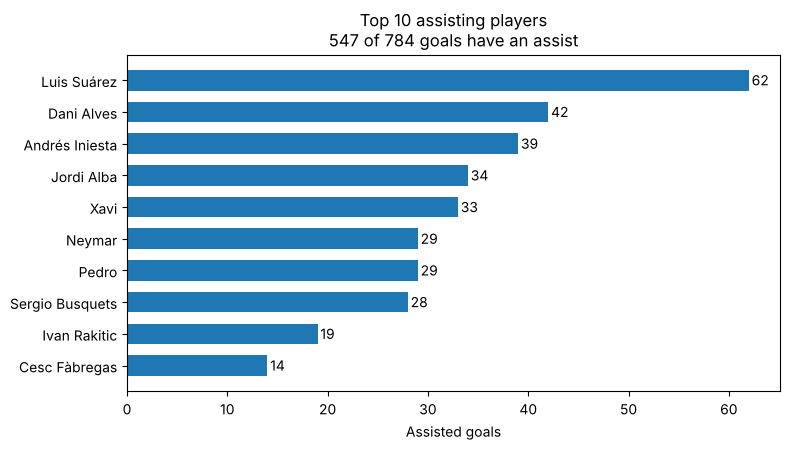

In [27]:
assisted = goals[goals["has_assist"]]
top_assisters = assisted["assist_player"].value_counts().head(10).sort_values()

figure, axes = plt.subplots(figsize=(8, 4.6))
bars = axes.barh(top_assisters.index, top_assisters.values, height=0.65)
axes.bar_label(bars, padding=2)
axes.set_xlabel("Assisted goals")
axes.set_title(f"Top 10 assisting players\n{len(assisted)} of {len(goals)} goals have an assist")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_top_assisters.png", dpi=150)

In [28]:
# Share of goals with an assist, by decade and by goal type.
by_decade = goals.groupby("goal_decade")["has_assist"].mean().round(3).rename("share with assist")
by_type = goals.groupby("goal_type")["has_assist"].mean().round(3).rename("share with assist")
print(by_decade.to_string())
print()
print(by_type.sort_values().to_string())

goal_decade
2000s    0.740
2010s    0.690
2020s    0.699

goal_type
Free kick     0.000
Penalty       0.000
Other         0.375
Right foot    0.837
Left foot     0.884
Header        0.893
Unknown       1.000


### 4.6 Goals per 90 minutes (StatsBomb)

One row per La Liga or Ligue 1 match Messi played, 577 matches in total. Cups, the Champions League and MLS are not covered.
Minutes are capped at 90 (stoppage time is not counted), so goals per 90 minutes is slightly overstated.

In [29]:
print(f"Matches: {len(league_matches)}, started: {int(league_matches['started'].sum())}")
print(f"Minutes: {int(league_matches['minutes_played'].sum())}, Messi goals: {int(league_matches['messi_goals'].sum())}")
print(f"Matches with at least one Messi goal: {league_matches['scored'].mean():.1%}")

Matches: 577, started: 518
Minutes: 47084, Messi goals: 494
Matches with at least one Messi goal: 55.3%


In [30]:
def summarize_per_90(grouped):
    # Appearances, starts, minutes, goals and goals per 90 minutes for each group.
    summary = grouped.agg(
        matches=("match_id", "size"),
        starts=("started", "sum"),
        minutes=("minutes_played", "sum"),
        goals=("messi_goals", "sum"),
    )
    summary["goals_per_90"] = (summary["goals"] / summary["minutes"] * 90).round(2)
    return summary


per_season = summarize_per_90(league_matches.groupby(["season", "club"]))
per_season

,,matches,starts,minutes,goals,goals_per_90
season,club,,,,,
2004-05,FC Barcelona,7,0,78,1,1.15
2005-06,FC Barcelona,17,11,911,6,0.59
2006-07,FC Barcelona,26,23,2000,14,0.63
2007-08,FC Barcelona,27,22,1920,8,0.38
2008-09,FC Barcelona,31,27,2517,23,0.82
2009-10,FC Barcelona,35,30,2843,34,1.08
2010-11,FC Barcelona,33,31,2859,31,0.98
2011-12,FC Barcelona,37,36,3269,50,1.38
2012-13,FC Barcelona,32,27,2648,46,1.56


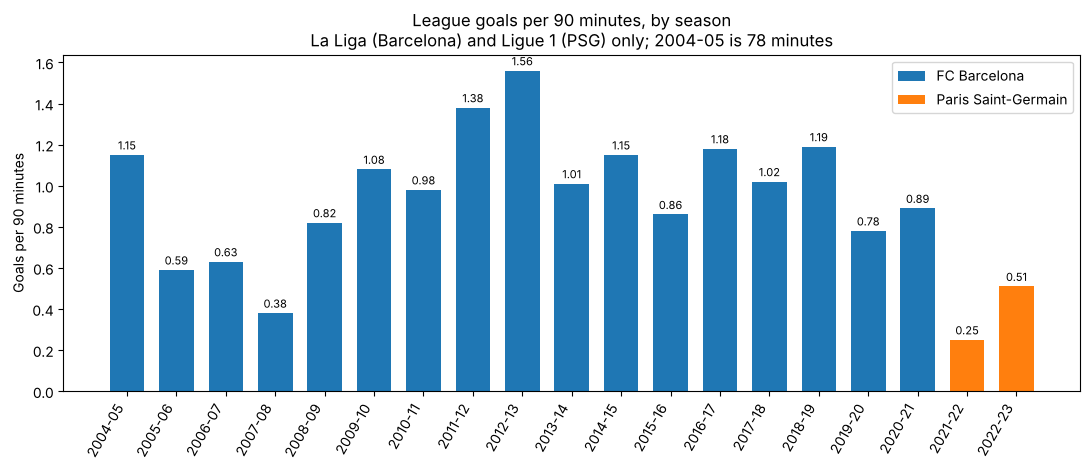

In [31]:
per_season_flat = per_season.reset_index()
x_positions = np.arange(len(per_season_flat))

figure, axes = plt.subplots(figsize=(11, 4.8))
for club in ["FC Barcelona", "Paris Saint-Germain"]:
    is_club = per_season_flat["club"] == club
    bars = axes.bar(
        x_positions[is_club], per_season_flat.loc[is_club, "goals_per_90"], width=0.7, label=club
    )
    axes.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)

axes.set_xticks(x_positions)
axes.set_xticklabels(per_season_flat["season"], rotation=60, ha="right")
axes.set_ylabel("Goals per 90 minutes")
axes.legend()
axes.set_title("League goals per 90 minutes, by season\nLa Liga (Barcelona) and Ligue 1 (PSG) only; 2004-05 is 78 minutes")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "eda_goals_per_90_by_season.png", dpi=150)

In [32]:
# Per club, and per starting position (starts only, because a substitute's
# recorded position is the position of the player he replaced).
per_club = summarize_per_90(league_matches.groupby("club"))
per_position = summarize_per_90(league_matches[league_matches["started"]].groupby("position_group"))
print("By club:")
print(per_club.to_string())
print()
print("By starting position (starts only):")
print(per_position.to_string())

By club:
                     matches  starts  minutes  goals  goals_per_90
club                                                              
FC Barcelona             519     462    42093    472          1.01
Paris Saint-Germain       58      56     4991     22          0.40

By starting position (starts only):
                    matches  starts  minutes  goals  goals_per_90
position_group                                                   
Attacking midfield       36      36     3210     31          0.87
Forward                 222     222    19658    229          1.05
Other                     1       1       90      0          0.00
Wing                    259     259    22351    205          0.83


In [33]:
# Team result when Messi scored vs did not score (counts and row shares).
result_counts = pd.crosstab(league_matches["scored"], league_matches["match_result"])[["W", "D", "L"]]
result_shares = result_counts.div(result_counts.sum(axis=1), axis=0).round(3)
print("Counts:")
print(result_counts.to_string())
print()
print("Shares:")
print(result_shares.to_string())

Counts:
match_result    W   D   L
scored                   
False         147  63  48
True          275  33  11

Shares:
match_result      W      D      L
scored                           
False         0.570  0.244  0.186
True          0.862  0.103  0.034


## 5. Observations and hypotheses

### What the data shows (descriptive only)

1. **Volume.** 784 goals in 512 matches, or 1.53 goals per scoring match. 298 matches have one goal, 164 have two, 43 have three and 7 have four or more. LaLiga is 60.5% of all goals and the Champions League is 16.5%.
2. **Over time.** The first goal is on 2005-05-01, so 2004-05 has a single goal. Goals per season rise to 17 in 2006-07 and 38 in 2008-09, peak at 73 in 2011-12, stay between 38 and 60 in most seasons up to 2018-19, and drop to 27 in 2019-20. After the move to PSG the seasons show 11 and 21 goals, and Inter Miami shows 25, 25 and 30 (the last one is partial).
3. **Goal type.** Left-footed shots are 62.5% of all goals (61%, 61% and 67% in the three decades). Penalties are 11% (88 goals) and direct free kicks 8% (59 goals).
4. **Position.** Position is tied to the period. In the 2000s, 87 of 96 goals (91%) are from RW. In the 2010s CF (267) is ahead of RW (205), and SS appears for the first time (43). Position and decade therefore move together and cannot be separated by this file alone.
5. **Minute.** The 76-90 bucket has the most goals (160, 20%) and 0-15 has the fewest (72, 9%). Bucket 91+ has 33 goals.
6. **Game state.** 418 goals (53%) came while the team was already winning, 275 (35%) while drawing and 91 (12%) while losing.
7. **Assists.** 547 of 784 goals (70%) have an assist, from 84 different players. Penalties and direct free kicks never have one; among all other goals the share is about 86%. The most frequent assisters are Luis Suárez (62), Dani Alves (42) and Andrés Iniesta (39).
8. **Selection effect.** 89% of goals (695 of 784) came in matches that the team won. This is partly because only matches where Messi scored are in the file, so it must not be read as "the team wins when he scores" without a comparison group.

**From the StatsBomb match table (La Liga and Ligue 1 only)**

9. **Coverage.** 577 league matches (518 starts) and 47,084 minutes. Messi scored in 55% of them; 494 of the 496 league goals in the goals file are matched (one 2007-08 match with 2 goals is missing from StatsBomb).
10. **Rate over time.** League goals per 90 minutes are between 0.38 and 0.63 from 2005-06 to 2007-08, above 1.0 in 8 of the 10 seasons from 2009-10 to 2018-19, and peak at 1.56 in 2012-13 (2004-05 is ignored: 78 minutes, 1 goal). The two PSG seasons are lower (0.25 and 0.51).
11. **By club and position.** About 1.01 goals per 90 at Barcelona against 0.40 at PSG (only 58 matches). As a starter, the rate is 1.05 when starting as a forward, 0.87 in attacking midfield and 0.83 on the wing.
12. **The comparison group.** The team won 86% of the matches in which Messi scored and 57% of those in which he did not. This replaces the one-sided figure in point 8, but it is still an association: weaker opponents make both a Messi goal and a win more likely.

### Candidate questions and hypotheses for the next notebooks

The goals file supports hypotheses on the **composition** of goals (shares of goal types, assists, minutes of the match). Scoring **rates** can be tested only for La Liga and Ligue 1, using the StatsBomb match table.

| # | Question | Hypothesis (H1) | Test | Caution |
|---|---|---|---|---|
| Q1 | How did scoring output change across seasons and clubs? | League goals per 90 minutes were lower at PSG (Ligue 1) than at Barcelona (La Liga) | Comparison of two Poisson rates (goals with minutes as exposure) | League matches only; PSG has 58 matches; also show the all-competition goals per season descriptively |
| Q2 | How has the way he scores changed over his career? | The mix of goal types differs between decades | Chi-square test of independence (goal type x decade) | The 2000s have only 96 goals; merge small goal types so every expected cell count is at least 5 |
| Q3 | Does his reliance on assists change by era? | The share of goals with an assist differs between decades | Chi-square test (has_assist x decade) | EDA shows 74%, 69% and 70%; "no difference" is a valid result |
| Q4 | When in the match do the goals come? | Goals are not spread evenly over the six 15-minute periods | Chi-square goodness-of-fit against an even split | Leave out bucket 91+, which is not a 15-minute period |
| Q5 | Do knockout goals look different from league goals? | The mix of goal types differs between knockout rounds and league matches | Chi-square test, or Fisher's exact test if cells are small | Knockout rounds have 151 goals in total (Final: 33); pool all knockout rounds |
| Q6 | Does his scoring rate depend on where he starts? | League goals per 90 minutes differ between starting position groups | Poisson regression of goals on position group, with minutes as exposure (add season to control for the period) | Starts only; position is tied to the period; StatsBomb records only the starting position |
| Q7 | Does the team win more often when Messi scores? | The team's win rate is higher in matches where Messi scored | Chi-square test (scored x result) | Association only; opponent strength affects both |

**Method notes**
- Goals in the same match are not fully independent (784 goals in 512 matches). Mention this as a limitation.
- Running several tests raises the chance of a false positive. Divide 0.05 by the number of tests you actually run (for example 0.05 / 6 is about 0.008).
- These hypotheses were written after looking at the data, so the tests are exploratory, not confirmatory.

**Still not answerable:** shot efficiency or xG, goals per 90 minutes outside La Liga and Ligue 1 (cups, Champions League, MLS), and anything about the national team.

Suggested next step as a team: choose four or five of Q1 to Q7 and test them in `02_hypothesis_testing`, one section per question.